## Video 2.2 - Solving our problem using HCA - Part 2

**Problem Statement**: Try out new-age bundled online marketing strategies which would require to group similiar products together irrespective of the segment.

### To perform clustering using HCA you will be following these steps:

1. __Load the Dataset:__ Import the pre-processed dataset.

2. __Processing and Feature Selection:__ Choose the features from the dataset that are relevant for the problem statement.

3. __Pre-process the data:__ Use appropriate pre-processing measures for the problem statement.

4. __Apply HCA to generate the dendrogram__

5. __Select the number of clusters using a threshold__

6. __Evaluate and Interpret the Clusters:__ By plotting different features with cluster labels.


In [7]:
import pandas as pd
import numpy as np
import os

os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module6')
data_preprocessed = pd.read_csv('Synergix_data_preprocessed_unsupervised_new.csv')
data_preprocessed.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,SKU1011,2021-01-02,4119.0,4650,6.671449,697,Makeup,29.0,21.0,49.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,SKU1011,2021-01-09,4074.0,11435,11.134372,1027,Makeup,36.0,28.0,62.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,SKU1011,2021-01-16,4897.0,11603,11.189007,1037,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,SKU1011,2021-01-23,4783.0,14067,11.880912,1184,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SKU1011,2021-01-30,3789.0,6188,7.063927,876,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# Define the aggregation operations
aggregation = {
    
    'Page_traffic':'last',
    'Organic Search Rank': 'last',
    'Image_Count': 'last',
    'Bullet_Count': 'last',
    'Title_Count': 'last',
    'Description_Length': 'last',
     '1_Star_Rating': 'last',
     '2_Star_Rating': 'last',
     '3_Star_Rating': 'last',
     '4_Star_Rating': 'last',
     '5_Star_Rating': 'last',  
    'Unit_price':'last',
    'Revenue($)': 'sum',
}

# Group by 'SKU_ID' and aggregate
# data_selected = data_preprocessed.groupby('SKU_ID').agg(aggregation).reset_index()
data_selected = data_preprocessed.groupby('SKU_ID').agg(aggregation)
data_selected

,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($)
SKU_ID,,,,,,,,,,,,,
SKU1011,4995.0,14.0,5.0,5.0,91.0,59.0,75.0,50.0,118.0,237.0,1672.0,18.095471,1805434
SKU1014,87.0,32.0,0.0,5.0,79.0,99.0,89.0,49.0,146.0,257.0,1651.0,20.099526,0
SKU1024,5454.0,30.0,0.0,8.0,163.0,158.0,106.0,66.0,205.0,440.0,2996.0,15.980161,2340227
SKU1025,5356.0,27.0,2.0,6.0,90.0,62.0,152.0,102.0,287.0,604.0,4098.0,19.634593,2432316
SKU1036,3627.0,24.0,12.0,8.0,126.0,221.0,140.0,78.0,228.0,474.0,3479.0,25.186318,2839170
...,...,...,...,...,...,...,...,...,...,...,...,...,...
SKU968,875.0,19.0,9.0,5.0,85.0,56.0,57.0,39.0,116.0,273.0,1803.0,20.905660,0
SKU978,6056.0,30.0,0.0,8.0,167.0,158.0,14.0,9.0,0.0,74.0,533.0,18.176868,2211515
SKU989,583.0,28.0,13.0,6.0,62.0,122.0,162.0,107.0,277.0,571.0,3809.0,20.905660,0


In [9]:
from sklearn.preprocessing import StandardScaler

# Standardize the numerical columns
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_selected)

# Create a DataFrame for the scaled data
data_scaled = pd.DataFrame(data_scaled, columns=data_selected.columns, index = data_selected.index)

# Show the first few rows of the scaled DataFrame
data_scaled.head()


,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($)
SKU_ID,,,,,,,,,,,,,
SKU1011,1.100784,-0.411851,-0.411446,-1.576290,-0.551930,-1.284448,-0.209573,-0.229204,-0.389066,-0.409205,-0.320630,-0.627850,-0.062109
SKU1014,-1.351049,1.041026,-1.427309,-1.576290,-0.962336,-0.632472,0.013749,-0.252124,-0.162427,-0.330060,-0.333027,-0.398543,-1.624228
SKU1024,1.330081,0.879595,-1.427309,1.486582,1.910506,0.329194,0.284926,0.137522,0.315134,0.394121,0.460978,-0.869888,0.400611
SKU1025,1.281125,0.637449,-1.020964,-0.555332,-0.586131,-1.235550,1.018701,0.962656,0.978863,1.043114,1.111530,-0.451741,0.480290
SKU1036,0.417388,0.395303,1.010763,1.486582,0.645087,1.356056,0.827281,0.412567,0.501302,0.528668,0.746111,0.183498,0.832313


> Only difference: **No k to specify upfront**. You let the tree grow first, then decide where to cut it.

### Step 4: Apply HCA to the dataset

**Purpose**: Perform the entire HCA algorithm and store the full merge history in a matrix called *links*.

In [10]:
import scipy.cluster.hierarchy as sch
links = sch.linkage(data_scaled, method='ward')
links

array([[1.53000000e+02, 1.55000000e+02, 2.77353140e-01, 2.00000000e+00],
       [1.23000000e+02, 2.22000000e+02, 2.98009999e-01, 2.00000000e+00],
       [8.20000000e+01, 2.28000000e+02, 3.37148236e-01, 2.00000000e+00],
       [7.40000000e+01, 2.12000000e+02, 6.40802371e-01, 2.00000000e+00],
       [1.30000000e+01, 2.34000000e+02, 7.13710658e-01, 2.00000000e+00],
       [1.51000000e+02, 2.18000000e+02, 7.67622264e-01, 2.00000000e+00],
       [4.80000000e+01, 7.80000000e+01, 7.85424852e-01, 2.00000000e+00],
       [1.46000000e+02, 2.07000000e+02, 7.99001719e-01, 2.00000000e+00],
       [5.00000000e+01, 1.52000000e+02, 8.51014936e-01, 2.00000000e+00],
       [4.50000000e+01, 1.21000000e+02, 8.93908183e-01, 2.00000000e+00],
       [1.33000000e+02, 1.59000000e+02, 9.06137590e-01, 2.00000000e+00],
       [1.15000000e+02, 1.72000000e+02, 9.24859449e-01, 2.00000000e+00],
       [1.00000000e+01, 1.64000000e+02, 9.41100440e-01, 2.00000000e+00],
       [1.66000000e+02, 1.89000000e+02, 9.86984875e

#### What **code** above does:
- *scipy.cluster.hierarchy* — HCA doesn't come from sklearn. It comes from SciPy, a scientific computing library. sklearn is optimized for predictive models; SciPy has better support for hierarchical methods.

- *sch.linkage(data_scaled, method='ward')* — this single line runs the entire bottom-up merging process. It returns a matrix where each row records one merge event:

```python
[cluster_A,  cluster_B,  distance,  size_of_new_cluster]
```
 If you have 200 products, you get 199 rows — one for each of the 199 merges it takes to go from 200 individual clusters down to 1.

**What *method='ward'* means — the linkage criterion:**

- When merging two clusters, *how do you measure the distance between them?* 
- Ward's method answers: merge the two clusters whose merging causes the **smallest increase in total within-cluster variance.** 
- In plain terms — always merge the two clusters that, when combined, stay the most compact.

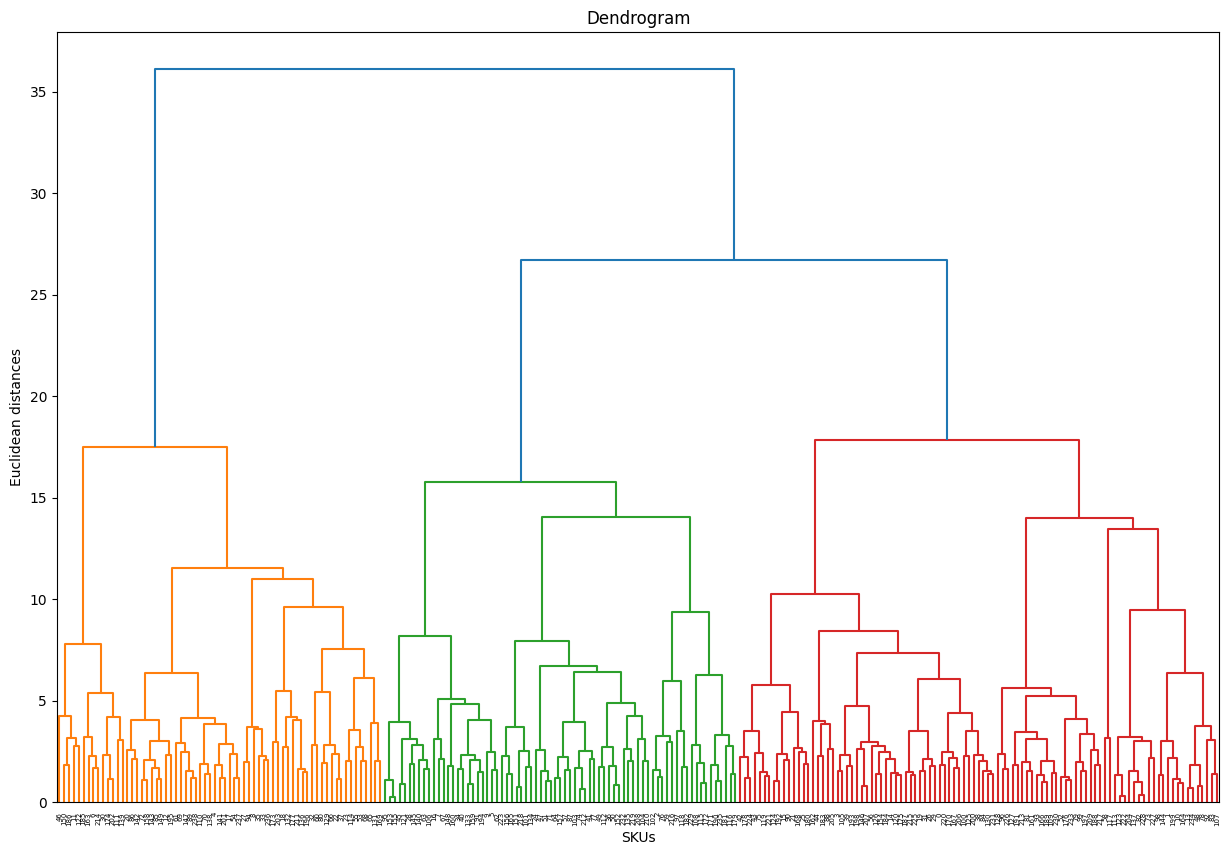

In [11]:
import matplotlib.pyplot as plt
# Generate a dendrogram
plt.figure(figsize=(15, 10))


dendrogram = sch.dendrogram(links)
plt.title('Dendrogram')
plt.xlabel('SKUs')
plt.ylabel('Euclidean distances')
plt.show()

**How to read a dendrogram**:

- **X-axis**: Individual products (SKUs) at the bottom — each leaf is one product
- **Y-axis**: The distance (dissimilarity) at which two clusters were merged — higher = more different
-**Horizontal lines**: Each horizontal line represents a merge. Two branches join together at the height equal to the distance between them when they merged
- **Vertical lines**: Connect parent clusters to their children


>**Key Insight**: Long vertical lines mean the two things being merged are **very different** — there was a big jump in distance. Short vertical lines mean they were close together. When you see a large gap between two horizontal merges, that gap is telling you: "*these two groups are naturally distinct — this is a good place to cut.*"

## Step 5: Selecting Clusters with a Threshold

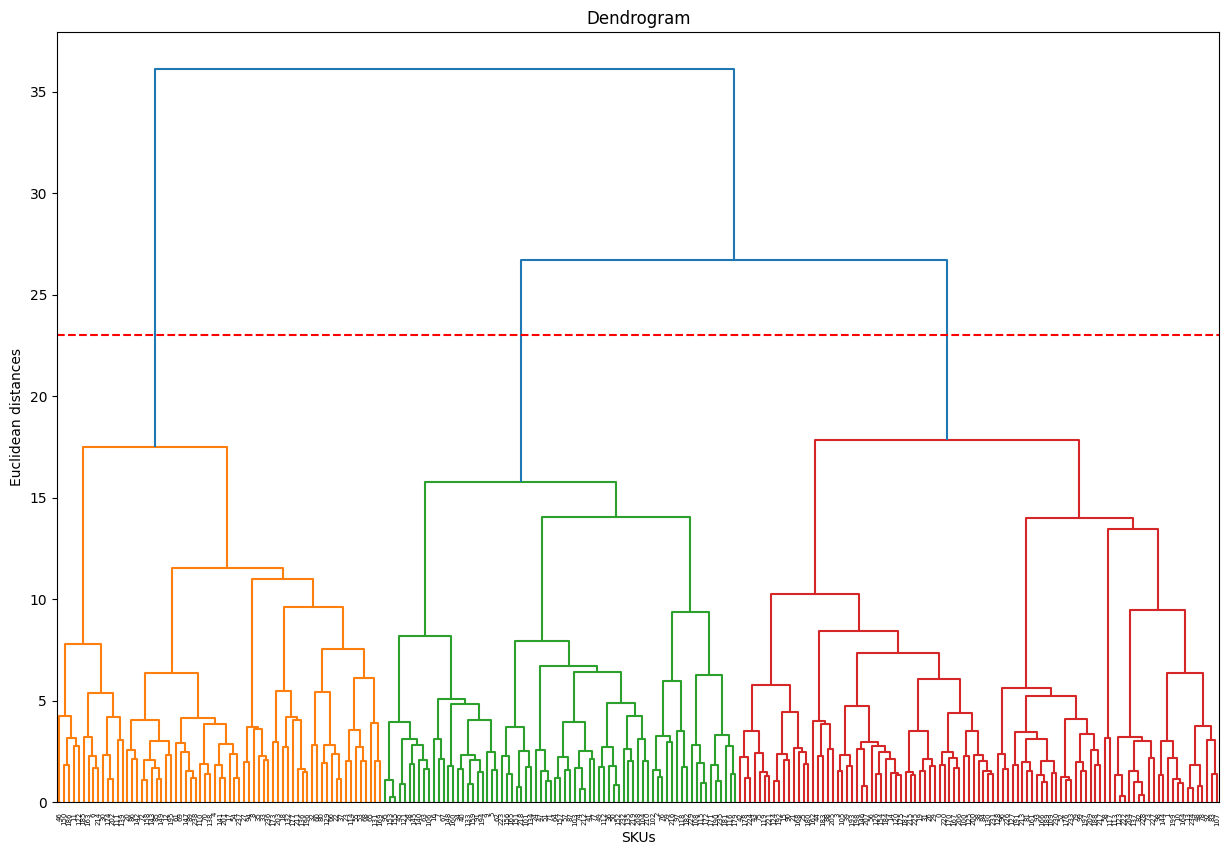

In [12]:
plt.figure(figsize=(15, 10))  
plt.title("Dendrogram")  
plt.title('Dendrogram')
plt.xlabel('SKUs')
plt.ylabel('Euclidean distances')
dend = sch.dendrogram(links)

# First attempt — threshold at y=23
plt.axhline(y=23, color='r', linestyle='--')

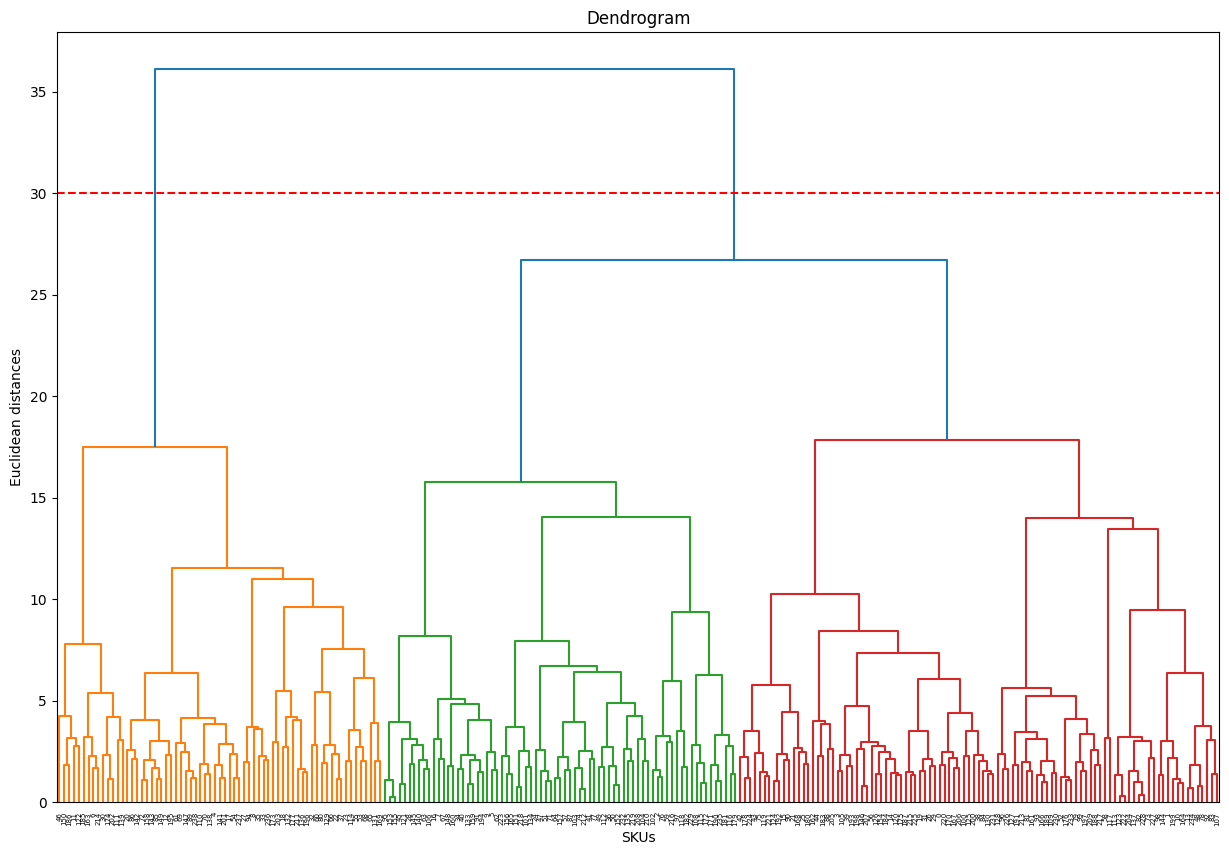

In [13]:
plt.figure(figsize=(15, 10))  
plt.title("Dendrogram")  
plt.title('Dendrogram')
plt.xlabel('SKUs')
plt.ylabel('Euclidean distances')
dend = sch.dendrogram(links)

# Second attempt — threshold at y=30
plt.axhline(y=30, color='r', linestyle='--')

## Step 6: Evaluate and Interpret the Clusters

In [14]:
from scipy.cluster.hierarchy import fcluster
cluster_labels = fcluster(links, t=30, criterion='distance')

# Add the cluster labels to your dataframe
data_scaled['Cluster_Labels'] = cluster_labels
data_scaled

,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($),Cluster_Labels
SKU_ID,,,,,,,,,,,,,,
SKU1011,1.100784,-0.411851,-0.411446,-1.576290,-0.551930,-1.284448,-0.209573,-0.229204,-0.389066,-0.409205,-0.320630,-0.627850,-0.062109,2
SKU1014,-1.351049,1.041026,-1.427309,-1.576290,-0.962336,-0.632472,0.013749,-0.252124,-0.162427,-0.330060,-0.333027,-0.398543,-1.624228,2
SKU1024,1.330081,0.879595,-1.427309,1.486582,1.910506,0.329194,0.284926,0.137522,0.315134,0.394121,0.460978,-0.869888,0.400611,2
SKU1025,1.281125,0.637449,-1.020964,-0.555332,-0.586131,-1.235550,1.018701,0.962656,0.978863,1.043114,1.111530,-0.451741,0.480290,2
SKU1036,0.417388,0.395303,1.010763,1.486582,0.645087,1.356056,0.827281,0.412567,0.501302,0.528668,0.746111,0.183498,0.832313,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SKU968,-0.957397,-0.008274,0.401245,-1.576290,-0.757133,-1.333346,-0.496702,-0.481328,-0.405255,-0.266743,-0.243296,-0.306303,-1.624228,2
SKU978,1.630816,0.879595,-1.427309,1.486582,2.047308,0.329194,-1.182622,-1.168940,-1.344188,-1.054241,-0.993025,-0.618537,0.289246,2
SKU989,-1.103268,0.718164,1.213936,-0.555332,-1.543745,-0.257585,1.178217,1.077258,0.897921,0.912524,0.940923,-0.306303,-1.624228,1


**Ideal Number of Clusters** - 2